In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import matplotlib
import matplotlib.pyplot as plt
import sigpy as sp
import pandas as pd
import sigpy.plot as pl
import numpy as np
import os
import sys
from pathlib import Path
import jax as jx
import time
import h5py


sys.path.insert(0,'/Users/ayman/Desktop/MSc Project Local/MSc-Project-ZTE')
import aymansigmri as asm

sys.path.insert(0, "/Users/ayman/Documents/GitHub/riesling/python")

import riesling as rlp


riesling_bin = Path.home() / "Documents" / "github" / "riesling" / "build" / "cxx" / "riesling"
os.environ["PATH"] += os.pathsep + str(riesling_bin)

save_dir = "/Users/ayman/Desktop/LowRank/Data Saved"

## Data

In [2]:
zte = '/Users/ayman/Desktop/LowRank/Data Saved/Brain/zte'
coorhires_zte = rlp.io.read_trajectory(f'{zte}.h5')
coorhires_zte = np.asarray(coorhires_zte)
kspacehires_zte = rlp.io.read_data(f'{zte}.h5')
kspacehires_zte = np.asarray(kspacehires_zte)
kspacehires_zte = kspacehires_zte[0, 0] 
kspacehires_zte = np.moveaxis(kspacehires_zte, -1, 0)

In [3]:
def h5tonum_interled(file, showshape=False, load_traj=True, stripdims=True):
    with h5py.File(file) as f:
        d = f['data'][:]
        if stripdims:
            d = d[0, 0]
        d = np.moveaxis(d,-1, 0)
        if load_traj:
            traj = f['trajectory'][:]
            if showshape:
                print(d.shape)
                print(traj.shape)
            return d, traj
        else:
            if showshape:
                print(d.shape)
            return d


In [4]:
zte_ksp, traj = asm.h5tonum_interleaved(f'{zte}.h5', showshape=True)

(18, 65278, 248)
(65278, 248, 3)


## Reshaping and Removing

In [5]:
cleaned_data = []
for coil in zte_ksp:
    if coil.shape[0] % 257 != 0:
        raise ValueError(f'{coil.shape[0]} spokes not divisible by 257')
    num_segments = coil.shape[0] // 257
    segments = np.split(coil, num_segments)[:-4] #split into segments
    cleaned_data.append(np.concatenate([s[1:] for s in segments], axis=0))

cleaned_data = np.stack(cleaned_data)

## Repeat for coords

num_segments_traj = traj.shape[0] // 257
segments_traj = np.split(traj, num_segments)[:-4]
cleaned_trajectory = np.concatenate([st[1:] for st in segments_traj], axis=0)

cleaned_trajectory.shape

(64000, 248, 3)

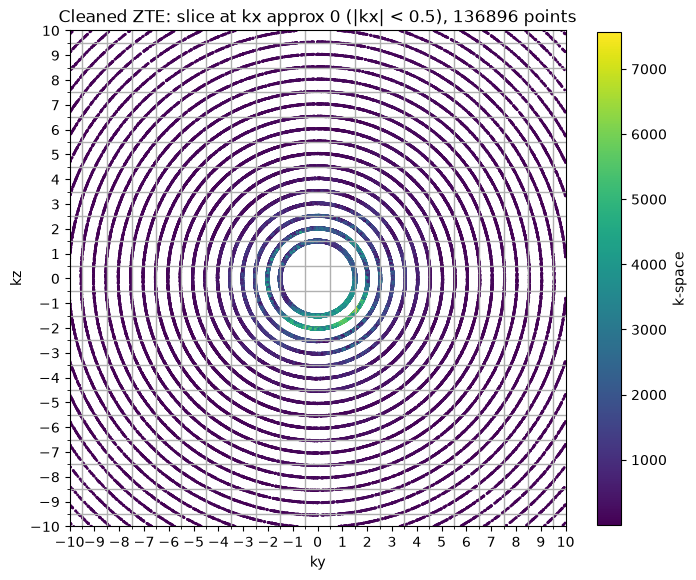

In [6]:
clean_coords = cleaned_trajectory.reshape(-1, 3)
clean_mag = np.abs(cleaned_data[0]).reshape(-1)

fig, ax1 = plt.subplots(figsize=(8, 8))

tol = 0.5  
mask_clean = (np.abs(clean_coords[:, 0]) < tol) \
           & (np.abs(clean_coords[:, 1]) < 10) \
           & (np.abs(clean_coords[:, 2]) < 10)

im1 = ax1.scatter(
    clean_coords[mask_clean, 1], clean_coords[mask_clean, 2],
    c=clean_mag[mask_clean],
    s=1
)
ax1.set_title(f'Cleaned ZTE: slice at kx approx 0 (|kx| < {tol}), {mask_clean.sum()} points')
ax1.set_xlabel('ky')
ax1.set_ylabel('kz')
ax1.set_aspect('equal')
ax1.xaxis.set_major_locator(plt.MultipleLocator(1))
ax1.yaxis.set_major_locator(plt.MultipleLocator(1))
ax1.grid(visible=True, which='minor', linewidth=1)
ax1.xaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
ax1.yaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
fig.colorbar(im1, ax=ax1, label='k-space', shrink=0.8)

plt.show()

In [ ]:
## Save cleaned data back to riesling .h5 format
# Original layout: data (t, slab, trace, sample, channel) = (1, 1, 65278, 248, 18)
#                  trajectory (trace, sample, k) = (65278, 248, 3), attr 'matrix'
zte_clean = f'{zte}_clean'

data_out = np.moveaxis(cleaned_data, 0, -1)[None, None].astype(np.complex64)  # (1, 1, 64000, 248, 18)
traj_out = cleaned_trajectory.astype(np.float32)                              # (64000, 248, 3)
assert data_out.shape[2:4] == traj_out.shape[:2]

with h5py.File(f'{zte}.h5', 'r') as src, h5py.File(f'{zte_clean}.h5', 'w') as out:
    d = out.create_dataset('data', data=data_out, chunks=True, compression='gzip')
    for i, label in enumerate(['t', 'slab', 'trace', 'sample', 'channel']):
        d.dims[i].label = label

    t = out.create_dataset('trajectory', data=traj_out, compression='gzip')
    # keep original matrix (252^3), stored as an HDF5 int64[3] array type like riesling writes it
    matrix = np.asarray(src['trajectory'].attrs['matrix']).reshape(-1)
    t.attrs.create('matrix', matrix, dtype=h5py.h5t.array_create(h5py.h5t.NATIVE_INT64, (3,)))

    src.copy('info', out)  # keep voxel size / origin / direction / tr

print(data_out.shape, traj_out.shape)



(1, 1, 64000, 248, 18) (64000, 248, 3)


In [8]:
!riesling op-nufft "{zte_clean}.h5" "{zte_clean}-nufft.h5" -v2

[21:52:31] [op-nufft] Welcome to RIESLING
[21:52:31] [H5    ] Opened /Users/ayman/Desktop/LowRank/Data Saved/Brain/zte_clean.h5 for reading id 72057594037927936
[21:52:32] [Traj  ] 3D Samples 248 Traces 64000 Matrix [252, 252, 252] FOV [252.00, 252.00, 252.00]
[21:52:32] [HD5   ] Opened /Users/ayman/Desktop/LowRank/Data Saved/Brain/zte_clean-nufft.h5 for writing id 72057594037927937
[21:52:44] [Kernel] Exponential Semi-Circle width 4 β 7.578488
[21:52:44] [Kernel] Width 4 Scale 1.892995e-09
[21:52:44] [Traj  ] Nominal FOV, matrix [252, 252, 252]
[21:52:44] [Traj  ] Nominal matrix [252, 252, 252] grid matrix [328, 328, 328] over-sampling [1.30, 1.30, 1.30]
[21:52:45] [Traj  ] 15680000 valid, 192000 invalid, 0 outside
[21:52:45] [Traj  ] Nominal FOV, matrix [252, 252, 252]
[21:52:45] [Kernel] Exponential Semi-Circle width 4 β 7.578488
[21:52:45] [Kernel] Width 4 Scale 1.892995e-09
[21:52:45] [Apodiz] Shape [252, 252, 252] Grid shape [328, 328, 328] Scale 4000.376
[21:52:45] [NUFFT ] isha

## Get this back to h5 so I can fft

In [24]:
zte_im, traj = asm.h5tonum(f'{zte_clean}-nufft.h5', showshape=True)

(18, 252, 252, 252)
(3, 64000, 248)


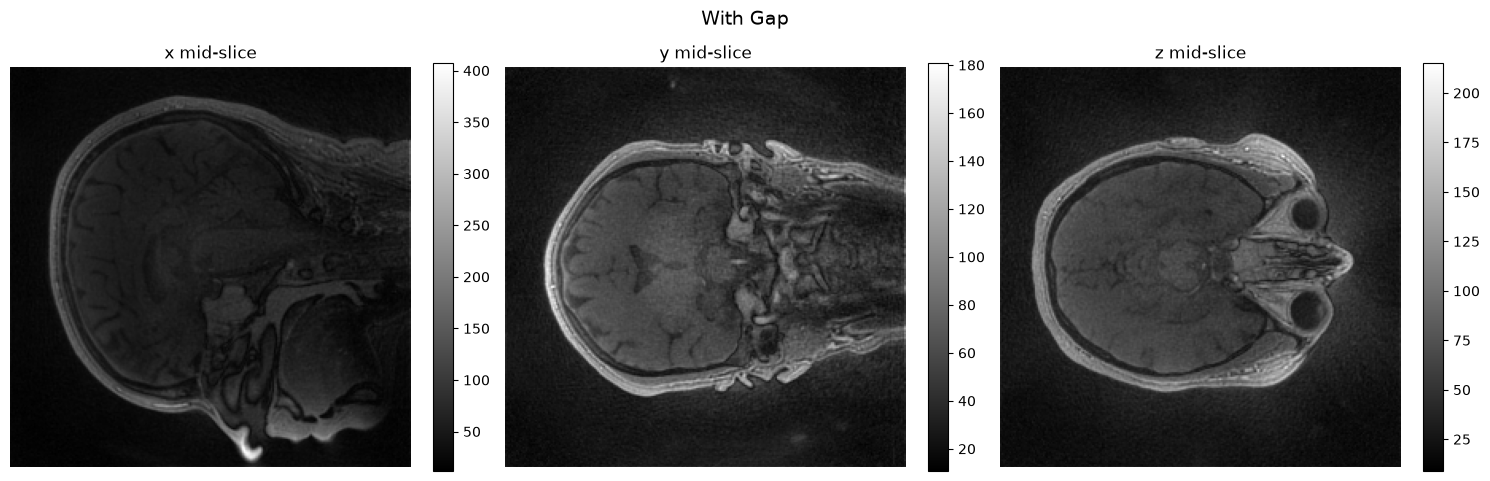

In [28]:
asm.plot_planes(zte_im, title='With Gap', inputtype_kspace=False)

In [34]:
waspi_im, traj = asm.h5tonum(f'{zte}-nufft.h5', showshape=True)

(18, 252, 252, 252)
(3, 65278, 248)


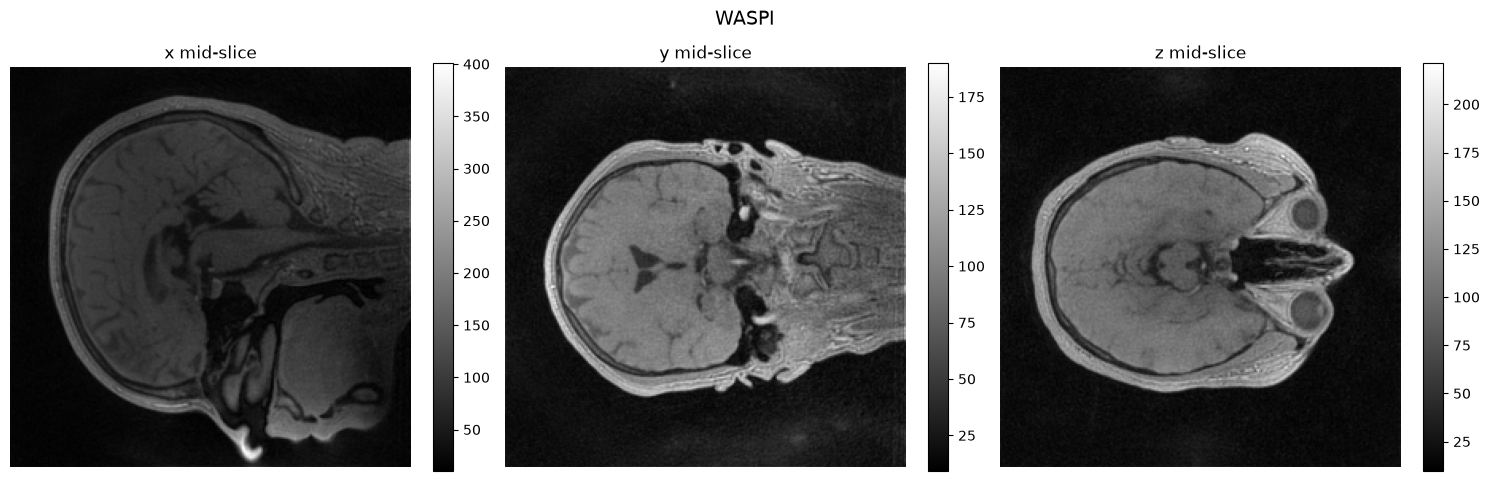

In [35]:
asm.plot_planes(waspi_im, title='WASPI', inputtype_kspace=False)